In [1]:
STUDENT_NAME = "Lê Thái Đức Tùng"
STUDENT_ID = "ITDSIU24055"
CLASS_GROUP = "IT171IU - Lab Group 01"
print(f"Lab 2 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 2 | Lê Thái Đức Tùng | ITDSIU24055 | IT171IU - Lab Group 01


In [ ]:
import numpy as np
import pandas as pd
from typing import cast
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize)

In [3]:
from ISLP import confusion_table
from ISLP.models import contrast
from sklearn.discriminant_analysis import \
     (LinearDiscriminantAnalysis as LDA,
      QuadraticDiscriminantAnalysis as QDA)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

<div class="alert alert-block alert-info">
<b>Note:</b> Em nhờ Claude viết ra hàm này để tránh cho Pylance (language server) báo lỗi trên máy em thôi ạ. 
</div>


In [ ]:
# [ADDED] helper – giữ đúng kiểu DataFrame cho Pylance
def design_matrix(terms, data) -> pd.DataFrame:
    """MS(...).fit_transform() thực tế trả về DataFrame, nhưng ISLP.build_model()
    không có type hint và có nhánh trả về np.ndarray (model_spec.py:647) bên cạnh
    nhánh trả về DataFrame (:662), nên Pylance suy ra kiểu union và gạch đỏ
    .columns / .values. Bọc lại một lần để Pylance báo đúng kiểu."""
    return cast(pd.DataFrame, MS(terms).fit_transform(data))

---

# <span style="color:red">4. Exercises</span>

<span style="color:red">For every exercise write **code + output + interpretation**. Exercises 1–6 are compulsory; 7–8 are challenge (bonus) exercises.</span>

## <span style="color:red">Exercise 1 – The `Weekly` stock market data</span>

<span style="color:red">The `Weekly` data contains 1,089 weekly returns (1990–2010) with the same variables as `Smarket`.</span>

- <span style="color:red">**(a)** Produce numerical and graphical summaries (`describe()`, correlation matrix, `Volume` over time). Do you see any pattern?</span>
- <span style="color:red">**(b)** Fit a logistic regression of `Direction` on the five lags and `Volume` using all the data. Which predictors appear statistically significant?</span>
- <span style="color:red">**(c)** Compute the confusion matrix and the overall fraction of correct predictions. Explain what the confusion matrix tells you about the types of mistakes.</span>

In [ ]:
# ✍️ Exercise 1 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
# load_data() không có type hint và trả về DataFrame cho hầu hết dataset nhưng
# dict cho 'NCI60'/'Khan', nên Pylance suy ra kiểu union và gạch đỏ .describe().
# cast() chỉ báo kiểu cho Pylance, không thay đổi gì lúc chạy.
Weekly = cast(pd.DataFrame, load_data('Weekly'))

# I need to see what this data is
Weekly

In [5]:
# (a) Produce numerical and graphical summaries (`describe()`, correlation matrix, `Volume` over time).
# Do you see any pattern?

# I'll show the numerical summaries
Weekly.describe()

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
count,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000
mean,2000.048669,0.150585,0.151079,0.147205,0.145818,0.139893,1.574618,0.149899
std,6.033182,2.357013,2.357254,2.360502,2.360279,2.361285,1.686636,2.356927
min,1990.000000,-18.195000,-18.195000,-18.195000,-18.195000,-18.195000,0.087465,-18.195000
25%,1995.000000,-1.154000,-1.154000,-1.158000,-1.158000,-1.166000,0.332022,-1.154000
50%,2000.000000,0.241000,0.241000,0.241000,0.238000,0.234000,1.002680,0.241000
75%,2005.000000,1.405000,1.409000,1.409000,1.409000,1.405000,2.053727,1.405000
max,2010.000000,12.026000,12.026000,12.026000,12.026000,12.026000,9.328214,12.026000


In [14]:
matrix = Weekly[["Year", "Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]].corr(numeric_only=True)
matrix

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume
Year,1.000000,-0.032289,-0.033390,-0.030006,-0.031128,-0.030519,0.841942
Lag1,-0.032289,1.000000,-0.074853,0.058636,-0.071274,-0.008183,-0.064951
Lag2,-0.033390,-0.074853,1.000000,-0.075721,0.058382,-0.072499,-0.085513
Lag3,-0.030006,0.058636,-0.075721,1.000000,-0.075396,0.060657,-0.069288
Lag4,-0.031128,-0.071274,0.058382,-0.075396,1.000000,-0.075675,-0.061075
Lag5,-0.030519,-0.008183,-0.072499,0.060657,-0.075675,1.000000,-0.058517
Volume,0.841942,-0.064951,-0.085513,-0.069288,-0.061075,-0.058517,1.000000


In [15]:
matrix.at["Volume", "Year"]

np.float64(0.8419416187031639)

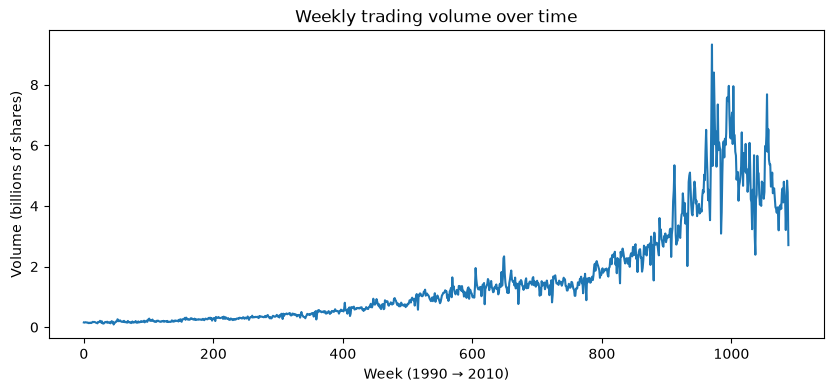

In [16]:
fig, ax = subplots(figsize=(10, 4))
ax.plot(Weekly['Volume'])
ax.set_xlabel('Week (1990 → 2010)')
ax.set_ylabel('Volume (billions of shares)')
ax.set_title('Weekly trading volume over time');

In [ ]:
vars_w = Weekly.columns.drop(['Today', 'Direction', 'Year'])
X_w = design_matrix(vars_w, Weekly)
y_w = Weekly['Direction'] == 'Up'
glm_w = sm.GLM(y_w, X_w, family=sm.families.Binomial()).fit()
summarize(glm_w)

In [19]:
# TODO (c): labels = np.where(glm_w.predict() > 0.5, 'Up', 'Down'); confusion_table(labels, Weekly['Direction'])
labels = np.where(glm_w.predict() > 0.5, 'Up', 'Down')
confusion_table(labels, Weekly['Direction'])

Truth,Down,Up
Predicted,,
Down,54,48
Up,430,557


In [ ]:
table = confusion_table(labels, Weekly['Direction'])
TP = table.loc['Up', 'Up']      # đoán Up, thực tế Up
FP = table.loc['Up', 'Down']    # đoán Up, thực tế Down
FN = table.loc['Down', 'Up']
TN = table.loc['Down', 'Down']

total_true = TP + TN
n = len(y_w)

print("Mean of accuracy = ", total_true / n)

Mean of accuracy =  0.5610651974288338


---

## <span style="color:red">Exercise 2 – Honest test error on `Weekly`</span>

<span style="color:red">Use the period **1990–2008** as training data and **2009–2010** as test data, with `Lag2` as the **only** predictor.</span>

- <span style="color:red">**(a)** Fit logistic regression, LDA, QDA, naive Bayes and KNN with $K=1$. For each method give the test confusion matrix and the test accuracy.</span>
- <span style="color:red">**(b)** Which method gives the best results? Try a few other values of $K$, transformations or interactions and report the best combination you find.</span>

In [ ]:
Weekly = cast(pd.DataFrame, load_data('Weekly'))

Weekly

In [ ]:
# ✍️ Exercise 2 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
train_w = Weekly['Year'] <= 2008
X_lag2 = Weekly[['Lag2']]
L_w = Weekly['Direction']

X3_tr, X3_te = X_lag2[train_w], X_lag2[~train_w]
y3_tr, y3_te = L_w[train_w], L_w[~train_w]

models = {
    "Logistic": LogisticRegression(),
    "LDA":      LDA(),
    "QDA":      QDA(),
    "NaiveBayes": GaussianNB(),
    "KNN K=1": KNeighborsClassifier(n_neighbors=1),
}

results_w = {}
for name, model in models.items():
    model.fit(X3_tr, y3_tr)
    pred = model.predict(X3_te)
    results_w[name] = {
        "model": model,
        "accuracy": np.mean(pred == y3_te),
        "pred": pred,
        "table":                confusion_table(pred, y3_te)
    }

In [ ]:
# Test accuracy for each model

for model, result in results_w.items():
    print(f"{model}: {result["accuracy"]}")

Logistic: 0.625
LDA: 0.625
QDA: 0.5865384615384616
NaiveBayes: 0.5865384615384616
KNN K=1: 0.5


In [ ]:
# Confusion matrix for each model

for model, result in results_w.items():
    print(f"{model}:\n{result["table"]}")
    print()

Logistic:
Truth      Down  Up
Predicted          
Down          9   5
Up           34  56

LDA:
Truth      Down  Up
Predicted          
Down          9   5
Up           34  56

QDA:
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61

NaiveBayes:
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61

KNN K=1:
Truth      Down  Up
Predicted          
Down         22  31
Up           21  30



In [18]:
# (b) Which method gives the best results? Try a few other values of $K$, transformations or interactions and report the best combination you find.
best_model = None
max_accuracy = 0

for model, item in results_w.items():
    if item["accuracy"] > max_accuracy:
        max_accuracy = item["accuracy"]
        best_model = model

print(f"Best model based on accuracy: {best_model} ({max_accuracy})")

Best model based on accuracy: Logistic (0.625)


---

## <span style="color:red">Exercise 3 – Predicting high and low gas mileage (`Auto`)</span>

- <span style="color:red">**(a)** Create a binary variable `mpg01` equal to 1 if `mpg` is above its median and 0 otherwise.</span>
- <span style="color:red">**(b)** Explore the association between `mpg01` and the other features graphically (box plots). Which features seem most useful?</span>
- <span style="color:red">**(c)** Split the data into a training set and a test set (`train_test_split`, `test_size=0.3`, `random_state=0`).</span>
- <span style="color:red">**(d)** Using the most useful features, fit LDA, QDA, logistic regression, naive Bayes and KNN (several $K$, with standardisation). Report the test error of each method in one table.</span>

In [ ]:
# ✍️ Exercise 3 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Auto = cast(pd.DataFrame, load_data('Auto'))

In [21]:
# (a) Create a binary variable `mpg01` equal to 1 if `mpg` is above its median and 0 otherwise.
Auto['mpg01'] = (Auto['mpg'] > Auto['mpg'].median()).astype(int)
Auto['mpg01']

name
chevrolet chevelle malibu    0
buick skylark 320            0
plymouth satellite           0
amc rebel sst                0
ford torino                  0
                            ..
ford mustang gl              1
vw pickup                    1
dodge rampage                1
ford ranger                  1
chevy s-10                   1
Name: mpg01, Length: 392, dtype: int64

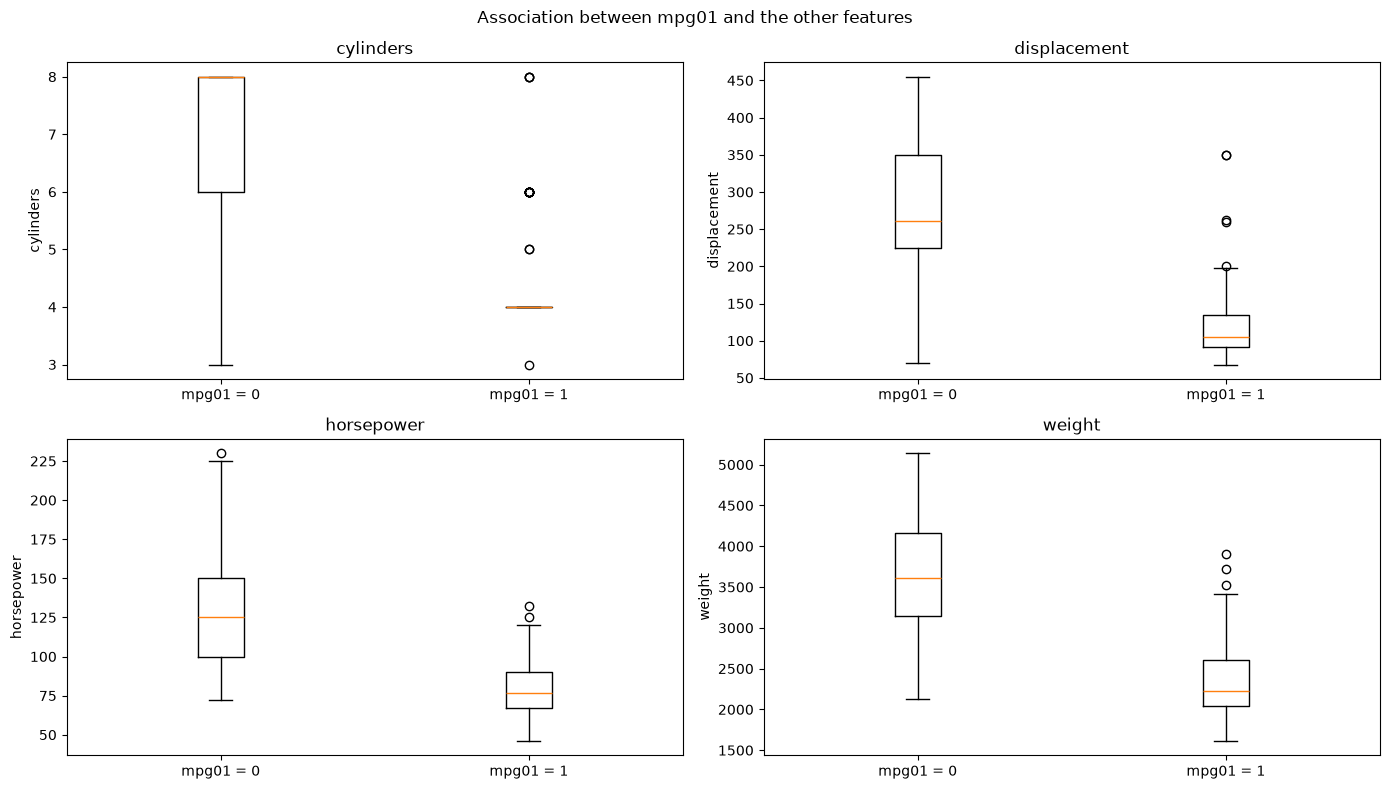

In [25]:
# **(b)** Explore the association between `mpg01` and the other features graphically (box plots). Which features seem most useful?
# Association ở đây nghĩa là phân bố

features = ['cylinders', 'displacement', 'horsepower', 'weight']   # TODO (b): justify / change

fig, axes = subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.flat, features):
    data = [Auto.loc[Auto['mpg01'] == 0, col],
            Auto.loc[Auto['mpg01'] == 1, col]]
    ax.boxplot(data, tick_labels=["mpg01 = 0", "mpg01 = 1"])
    ax.set_title(col)
    ax.set_ylabel(col)
fig.suptitle("Association between mpg01 and the other features")
fig.tight_layout()

In [ ]:
# (c)
X3_tr, X3_te, y3_tr, y3_te = train_test_split(Auto[features], Auto['mpg01'], test_size=0.3, random_state=0)

In [29]:
# TODO (d)
features = ['cylinders', 'displacement', 'horsepower', 'weight']

scaler = StandardScaler()
X3_tr_s = scaler.fit_transform(X3_tr)
X3_te_s = scaler.fit_transform(X3_te)

models = {
    "LDA":      LDA(),
    "QDA":      QDA(),
    "Logistic": LogisticRegression(),
    "NaiveBayes": GaussianNB(),
}
for k in [1, 3, 5, 10, 20, 50]:
    models[f"KNN K={k}"] = KNeighborsClassifier(n_neighbors=k)

results_w = {}
for name, model in models.items():
    Xtr, Xte = (X3_tr_s, X3_te_s) if name.startswith("KNN") else (X3_tr, X3_te)
    model.fit(X3_tr, y3_tr)
    pred = model.predict(X3_te)
    results_w[name] = {
        "model": model,
        "pred": pred,
        "test_error": np.mean(pred != y3_te),
        "accuracy": np.mean(pred == y3_te),
        "table": confusion_table(pred, y3_te)
    }

error_table = pd.DataFrame({
    "Test error": {n: r["test_error"] for n, r in results_w.items()},
    "Accuracy":   {n: r["accuracy"]   for n, r in results_w.items()},
}).sort_values("Test error")
error_table

,Test error,Accuracy
KNN K=3,0.127119,0.872881
LDA,0.135593,0.864407
NaiveBayes,0.135593,0.864407
Logistic,0.135593,0.864407
QDA,0.144068,0.855932
KNN K=1,0.152542,0.847458
KNN K=5,0.161017,0.838983
KNN K=10,0.161017,0.838983
KNN K=20,0.169492,0.830508
KNN K=50,0.169492,0.830508


---

## <span style="color:red">Exercise 4 – Logistic regression on `Default` with a validation set</span>

- <span style="color:red">**(a)** Fit a logistic regression of `default` on `income` and `balance`.</span>
- <span style="color:red">**(b)** Estimate the test error with the validation-set approach (half of the data for training). Repeat with three different `random_state` values. How variable is the estimate?</span>
- <span style="color:red">**(c)** Add the dummy variable `student`. Does it reduce the test error?</span>
- <span style="color:red">**(d)** Interpret the coefficient of `student[Yes]` as an odds ratio. Why can students have a *lower* default probability at a fixed balance but a *higher* overall default rate?</span>

In [ ]:
# ✍️ Exercise 4 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Default = cast(pd.DataFrame, load_data('Default'))
Default

In [ ]:
# (a) Fit a logistic regression of `default` on `income` and `balance`.
vars_w = ['balance', 'income']       # MS() nhận TÊN cột, không nhận DataFrame
X_w = design_matrix(vars_w, Default)
y_w = Default['default'] == 'Yes'    # Default không có cột 'Direction' như Weekly
glm_w = sm.GLM(y_w, X_w, family=sm.families.Binomial()).fit()
summarize(glm_w)

In [ ]:
for seed in [0, 1, 2]:
    pass   # TODO (b): split, fit sm.GLM(..., family=sm.families.Binomial()), compute the validation error